# A small language model from scratch, masked diffusion mode

This notebook builds a small language model from nothing that generates text by starting from a fully masked window and revealing positions in random order until the text is complete. The sibling notebook, `slm_autoregressive.ipynb`, trains the same architecture, with weights of its own, in the autoregressive mode, and the two deliberately repeat the boxes they share, so that each can be read on its own.

Each section corresponds to a box of the project's architecture diagram and is told in three parts. The theory comes broken down into mathematical building blocks, the application runs the code and shows what goes in and what comes out, and the technique covers the problems the project met and how they were solved. Nothing here uses pretrained weights or a pretrained tokenizer.

Project, decisions and references at [https://github.com/pcbrom/homebrewed-slms](https://github.com/pcbrom/homebrewed-slms). The corpora are Brazilian Portuguese, so the texts and samples below are in Portuguese. A Portuguese version of this notebook sits in the `notebooks/` folder. To run it in Colab, choose **Runtime, Change runtime type, T4 GPU** and run the cells in order.

If you find this material useful, please star the repository and cite it through `CITATION.cff`.

### A note on the code

The package `slm/` is written with Portuguese identifiers, and this notebook keeps them, because they are the exact code that produced the results reported in the project. The ones you will meet most often are below. By programming convention identifiers carry no accents, so the two modes appear in the code as `autoregressivo` and `difusao`.

| Identifier | Meaning | Identifier | Meaning |
|---|---|---|---|
| `treino`, `validacao`, `teste` | training, validation, test | `treinar` | train |
| `corpus`, `documentos` | corpus, documents | `ler_documentos` | read documents |
| `tokenizador` | tokenizer | `janelas`, `janelar` | windows, cut into windows |
| `mascaramento`, `mascarar` | masking, apply masks | `modelo`, `rede` | model, network |
| `perda` | loss | `epocas`, `lote` | epochs, batch |
| `geracao`, `gerar_ar`, `gerar_difusao` | generation, generate | `avaliacao`, `avaliar` | evaluation, evaluate |
| `calibracao` | calibration | `delecao` | deletion |
| `leitura` | reading | `amostras` | samples |
| `passos_aplicados`, `passos_pulados` | applied steps, skipped steps | `tempo_s`, `perda_final` | time in seconds, final loss |
| `sem_embedding`, `com_embedding` | without, with the embedding | `particao`, `grupo` | partition, group |

In [1]:
import os, subprocess, sys
LOCAL = os.environ.get("SLM_LOCAL")
if LOCAL:
    RAIZ = LOCAL
else:
    RAIZ = "/content/homebrewed-slms"
    if not os.path.exists(RAIZ):
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/pcbrom/homebrewed-slms", RAIZ], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "tokenizers==0.23.3", "regex"], check=True)
sys.path.insert(0, RAIZ)
os.chdir(RAIZ)
import torch
DISPOSITIVO = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DISPOSITIVO, torch.cuda.get_device_name(0) if DISPOSITIVO == "cuda" else "")

device: cuda NVIDIA GeForce RTX 5090


## The whole pipeline

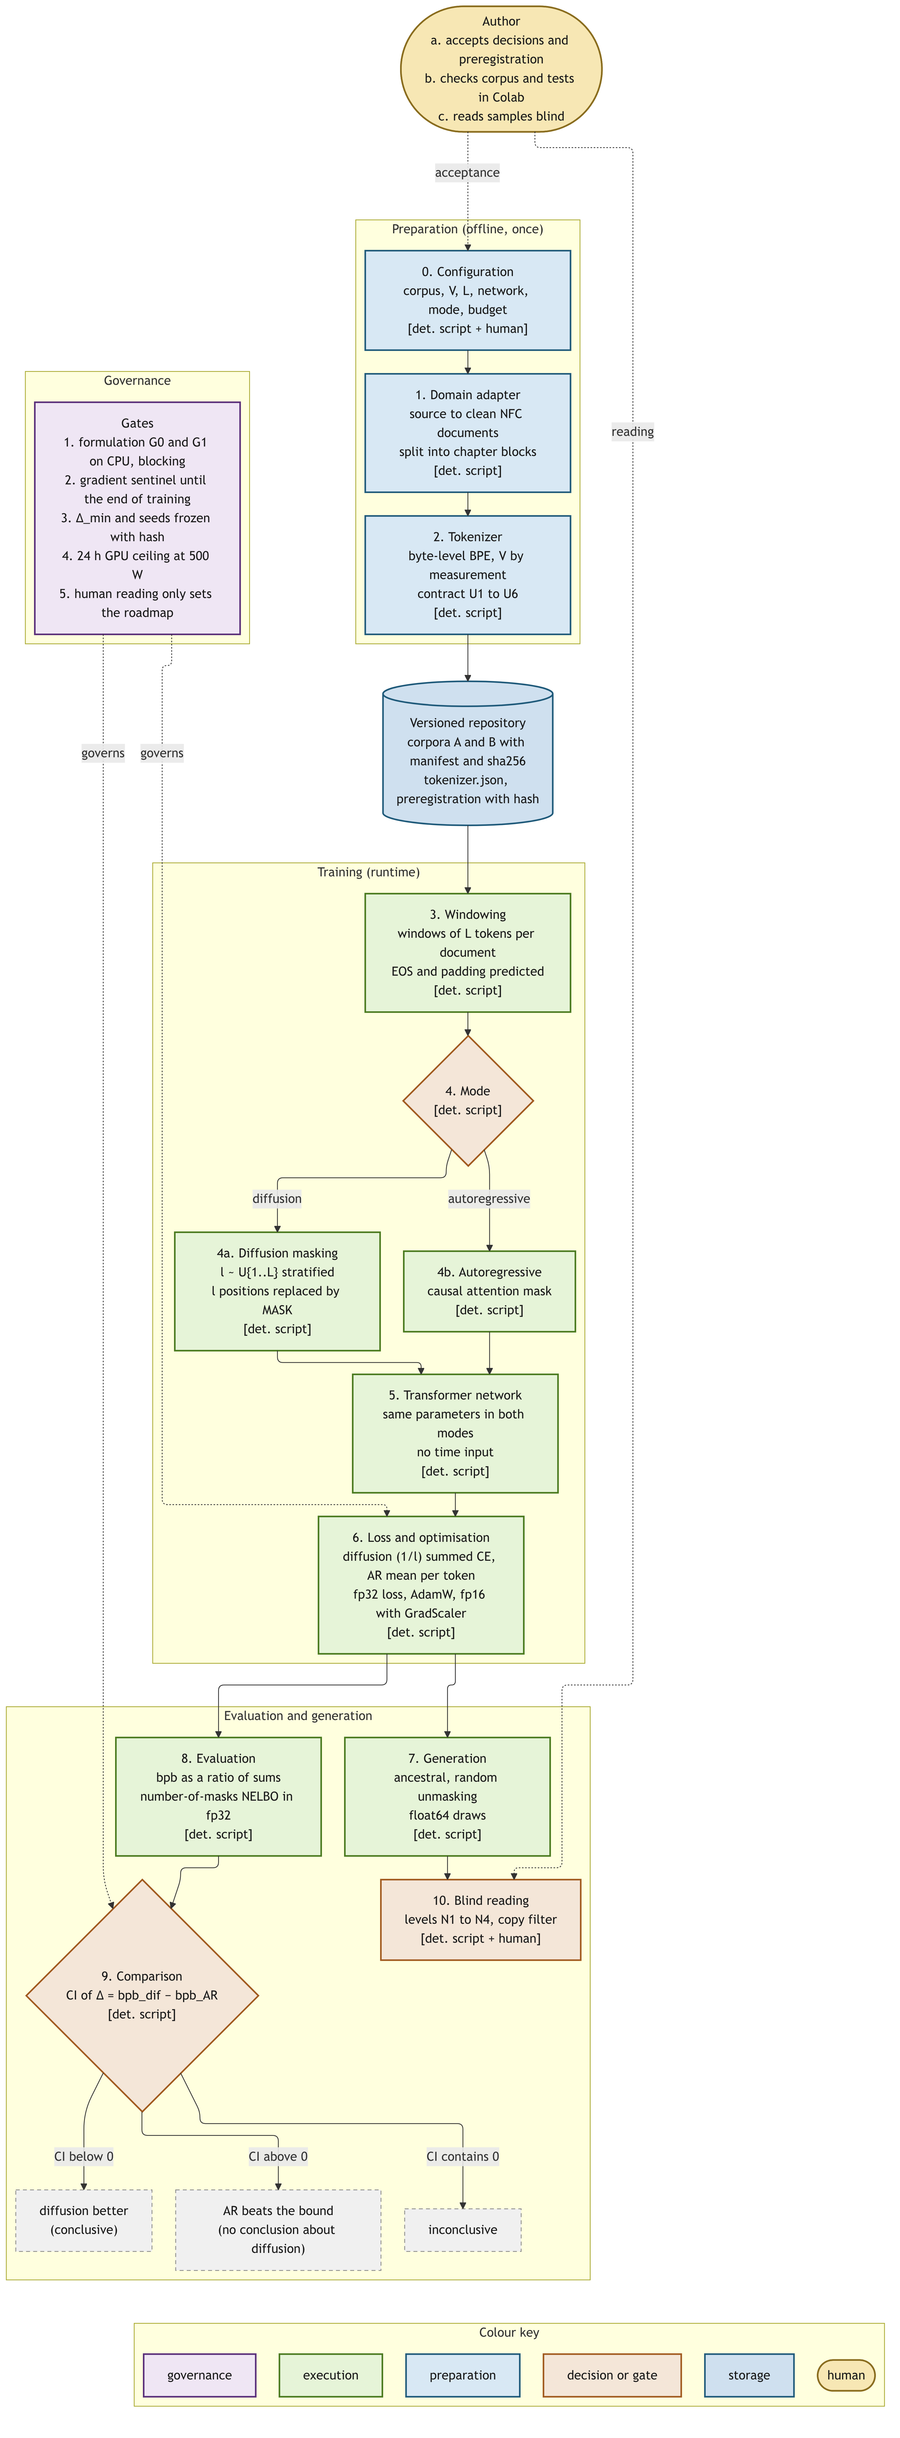

Preparation (boxes 0 to 2) runs once and leaves the clean corpus and the tokenizer in the repository. Training (boxes 3 to 6) is the same in both modes up to box 4, where diffusion replaces tokens by `[MASK]` and the autoregressive mode uses causal attention. Evaluation and generation (boxes 7 to 10) measure what the model has learned. This notebook follows the diffusion branch of box 4, where tokens are replaced by `[MASK]`.

## Mathematical map, from text to measurement

Each box takes in one mathematical object and hands on another. The table fixes the notation used throughout the notebook, and the chain just below shows how the blocks fit together.

| Symbol | Meaning | Where it arises |
|---|---|---|
| $d$, $B_d$ | a document (chapter or law) and its length in bytes in UTF-8, after NFC | box 1, `slm/dados.py` |
| $\tau(d) = (t_1, \dots, t_n)$ | token ids of the document, with $t_i \in \{4, \dots, V-1\}$ | box 2, `slm/tokenizador.py` |
| $w \in \{0, \dots, V-1\}^L$ | a window of $L$ tokens | box 3, `slm/janelas.py` |
| $l$, $S$, $z$ | number of masks, masked set, masked window | box 4, `slm/mascaramento.py` |
| $f_\theta$, $p_\theta$ | network with parameters $\theta$ and the conditional distributions it defines | box 5, `slm/modelo.py` |
| $\hat\ell_{dif}(w)$ | NELBO estimate for one window, in nats | box 6, `slm/perda.py` |
| $\mathrm{NLL}(d)$, $\mathrm{bpb}$ | loss of a document and bits per byte | box 8, `slm/avaliacao.py` |
| CI | confidence interval for the bits per byte | box 9, `slm/estatistica.py` |

Some symbols carry two meanings, and the context keeps them apart. $d$ is both a document and the width of the network, $S$ is both the masked set and the GradScaler scale, $T$ is both the number of generation steps and the temperature, $K$ is both the key matrix and the number of estimates per window, and $t$ is diffusion time whereas $t_i$ is a token. The network's logits are written $o$ so that they cannot be confused with the masked window $z$.

$$
\underbrace{d}_{\text{box 1}}
\xrightarrow{\ \tau\ }
\underbrace{(t_1,\dots,t_n)}_{\text{box 2}}
\xrightarrow{\ \oplus\,\mathrm{EOS},\ \text{cut at } L\ }
\underbrace{w}_{\text{box 3}}
\xrightarrow{\ \text{mask}\ }
\underbrace{z}_{\text{box 4}}
\xrightarrow{\ f_\theta\ }
\underbrace{p_\theta(\cdot \mid z)}_{\text{box 5}}
\xrightarrow{\ -\log\ }
\underbrace{\hat\ell_{dif}(w)}_{\text{box 6}}
\xrightarrow{\ \sum_{w \in d}\ }
\underbrace{\mathrm{NLL}(d)}_{\text{box 8}}
\xrightarrow{\ \sum_d / (\ln 2 \sum_d B_d)\ }
\underbrace{\mathrm{bpb} \pm \mathrm{CI}}_{\text{boxes 8 and 9}}
$$

Training (box 6) closes a loop over this chain, because the gradient of the loss with respect to $\theta$ flows back into box 5 and changes $f_\theta$. Generation (box 7) runs through the same $p_\theta$ in the opposite direction, from masks to text, revealing positions in random order.

## Box 0. Configuration

> **What changes from the autoregressive notebook.** The configuration is the same, except for `MODO`, which here is `"difusao"` and in the autoregressive notebook is `"autoregressivo"`. The technique gives the measured throughput of this mode.

### Theory

A run is described by a single object. Changing the domain, the size of the network or the mode means changing fields here, and nothing else. `CORPUS` chooses the training text, `"A"` for the prose of Machado de Assis and `"B"` for Brazilian federal laws, and `EPOCAS_AULA` sets how many times the live training goes over the text.

Before training, it is worth estimating how much text your GPU processes per hour and how much text the model needs to see. The full derivation is in `docs/DIMENSIONAMENTO.md`, and the cell below runs the same calculation for a T4. The script prints its table in Portuguese, where *pico* is peak, *tempo* is time, *orcamento* is budget, *otimo* is optimal and *custo de atencao* is the attention cost above $6N$.

### Building blocks

**Block 0.1, parameters excluding the embedding.** Each Transformer block has the attention projections $Q$, $K$ and $V$ plus the output projection, which together come to $4d^2$ weights, and an MLP of width $4d$, with $8d^2$ weights. Hence $N = 12\, n_{layer}\, d^2$, ignoring biases and normalisations. Code in `scripts/dimensionar.py`.

**Block 0.2, cost of one training token.** The forward pass costs $2N$ in the matrix products of the layers, $2\, n_{layer}\, L\, d$ in the attention product $QK^\top$ and $2\, d\, V$ in the output projection. This is the convention of Kaplan et al. (2020). PaLM (Chowdhery et al., 2022) also counts the product of the attention weights with the values, which doubles the attention term. Backpropagation costs roughly twice as much as the forward pass, so that, under Kaplan's convention,

$$C_{train} = 6N + 6\, n_{layer}\, L\, d + 6\, d\, V.$$

**Block 0.3, throughput and time.** With peak $P$ and utilisation MFU, the throughput is $P \cdot \mathrm{MFU} / C_{train}$ tokens per second, and the time needed to see $D$ tokens is $D$ divided by it. This is the number that decides how many epochs and how many seeds fit within the budget of boxes 6 and 9.

In [2]:
n_layer, d, L_, V_ = 6, 384, 256, 4096
N = 12 * n_layer * d * d
C = 6 * N + 6 * n_layer * L_ * d + 6 * d * V_
print(f"N = {N:,} | C_train = {C / 1e6:.1f} MFLOP per token | {C / (6 * N) - 1:.1%} above 6N")

N = 10,616,832 | C_train = 76.7 MFLOP per token | 20.4% above 6N


### Application

In [3]:
from slm.config import Config
MODO = "difusao"
CORPUS = os.environ.get("SLM_CORPUS", "A")
EPOCAS_AULA = float(os.environ.get("SLM_EPOCAS", "16"))
cfg_base = dict(L=256, n_layer=6, d=384, n_head=6, lote=64, epocas=EPOCAS_AULA, lr=1e-3,
                precisao="fp16" if DISPOSITIVO == "cuda" else "fp32",
                atencao="efficient" if DISPOSITIVO == "cuda" else "math", papel="aula", corpus=CORPUS)
print("mode:", MODO, "|", cfg_base)
print(subprocess.run([sys.executable, "scripts/dimensionar.py", "--pico-tflops", "65", "--vram-gb", "16",
                      "--arq", "6x384", "--vocab", "4096", "--horas", "0.25"],
                     check=True, capture_output=True, text=True).stdout)

mode: difusao | {'L': 256, 'n_layer': 6, 'd': 384, 'n_head': 6, 'lote': 64, 'epocas': 16.0, 'lr': 0.001, 'precisao': 'fp16', 'atencao': 'efficient', 'papel': 'aula', 'corpus': 'A'}
pico 65.0 TFLOPS | VRAM 16.0 GB | ctx 256 | vocab 4096 | 20 tokens/param (com embedding)

    arq       N   N+emb  FLOP/tok  extra mem AdamW tokens alvo    tok/s@0.3  tempo@0.3    tok/s@0.5  tempo@0.5
  6x384   10.6M   12.2M     76.7M    20%     1.1%V      243.8M       254.3k     16 min       423.9k     10 min

extra: custo de atencao e da camada de saida acima de 6N | mem AdamW: fracao da VRAM antes das ativacoes

orcamento de 0.25 h, aproximacao C = 6 N D com D = 20 N:
  MFU 0.3: C = 1.76e+16 FLOP, N otimo ~ 12.1M, D ~ 241.9M tokens
  MFU 0.5: C = 2.92e+16 FLOP, N otimo ~ 15.6M, D ~ 312.2M tokens



### Technique

**The short formula misleads for a small model.** The usual cost estimate, $6N$ operations per token, ignores attention and the output layer over the vocabulary. In a model with 4 layers, $d = 256$ and a vocabulary of 8 thousand tokens, these two terms add 73% to the cost, 65 points from the output layer and 8 from attention. `scripts/dimensionar.py` uses the full formula.

**Estimate, then measure.** The fraction of peak throughput that training actually achieves (MFU) cannot be read off the spec sheet. On an RTX 5090 capped at 500 W, diffusion processed 1.04 million tokens per second in fp16, slightly below the autoregressive mode (1.13 million). That gives an MFU of 0.38 when attention counts only the $QK^\top$ product, the convention of Kaplan et al. (2020), and 0.40 when it also counts the product with the values, the PaLM convention (Chowdhery et al., 2022). The 209.5 TFLOPS peak in the denominator comes from secondary sources and has not been checked against NVIDIA's technical documentation. At the measured throughput, the research plan would fit into about 5.6 hours of training, excluding evaluation, whereas the estimate made without measurement ranged from 7.5 to 45 hours.

## Box 1. Domain adapter

> **What changes from the autoregressive notebook.** Nothing. This box is identical in both notebooks.

### Theory

Text from a source goes in, and clean NFC documents come out, each with a group, a partition and a byte count.

Corpus A gathers the prose works of Machado de Assis from Project Gutenberg, in the public domain and in the original spelling of the period editions ("elle", "annos"). Each chapter is a document. The split reserves for validation and test contiguous blocks of whole chapters from each work, with one margin chapter before each held-out block, and the tokenizer is trained only after the split, so that no statistic of the evaluation text leaks into the vocabulary. The script output below keeps the partition names of the package, `treino` (training), `margem` (margin), `validacao` and `teste`.

### Building blocks

**Block 1.1, normalisation.** Every text goes through $u \mapsto \mathrm{NFC}(u)$, the canonical composed form of Unicode. Once it has been applied, every accented character in Portuguese is a single code point.

**Block 1.2, bytes.** $B_d = |\mathrm{UTF8}(\mathrm{NFC}(d))|$. It is the denominator of the bits per byte in box 8, which is why it is counted here, once and only once, and never on the text that the tokenizer reconstructs.

**Block 1.3, partition.** Each work is a sequence of chapters $c_1, \dots, c_m$. The split sends an opening block to training, one chapter to a margin, a contiguous block to validation, another chapter to a margin and the closing block to test, with every held-out block holding at least 5 chapters and 30 KB. *Papéis avulsos*, with 12 short stories, only has room for the validation block and stays out of the test set. The partition is a function of the document and is fixed before any training takes place. Code in `slm/dados.py`.

In [4]:
import unicodedata
from slm.corpus import ler_documentos
docs = ler_documentos(CORPUS)
d0 = docs[0]
print(d0["doc_id"], "| already in NFC:", unicodedata.is_normalized("NFC", d0["texto"]),
      "| B_d recounted:", len(d0["texto"].encode("utf-8")), "= stored bytes:", d0["bytes"])

A-55752-c001 | already in NFC: True | B_d recounted: 1956 = stored bytes: 1956


### Application

In [5]:
import collections
from slm.corpus import ler_documentos
docs = ler_documentos(CORPUS)
por_particao = collections.Counter(d["particao"] for d in docs)
bytes_particao = collections.Counter()
for d in docs:
    bytes_particao[d["particao"]] += d["bytes"]
for p in ("treino", "margem", "validacao", "teste"):
    print(f"{p:10s} {por_particao[p]:5d} documents {bytes_particao[p] / 1e6:7.3f} MB")
exemplo = next(d for d in docs if d["particao"] == "treino")
print("\nexample:", exemplo["doc_id"], exemplo["grupo"], exemplo["bytes"], "bytes")
print(exemplo["texto"][:600])

treino       650 documents   2.221 MB
margem        19 documents   0.177 MB
validacao    109 documents   0.540 MB
teste        110 documents   0.475 MB

example: A-55752-c001 dom_casmurro 1956 bytes
Do titulo.

Uma noite destas, vindo da cidade para o Engenho Novo, encontrei no trem da Central um rapaz aqui do bairro, que eu conheço de vista e de chapéo. Comprimentou-me, sentou-se ao pé de mim, falou da lua e dos ministros, e acabou recitando-me versos. A viagem era curta, e os versos póde ser que não fossem inteiramente maus. Succedeu, porém, que como eu estava cançado, fechei os olhos tres ou quatro vezes; tanto bastou para que elle interrompesse a leitura e mettesse os versos no bolso.

--Continue, disse eu accordando.

--Já acabei, murmurou elle.

--São muito bonitos.

Vi-lhe fazer um


### Technique

**A work "in prose" that was not only prose.** *Relíquias de casa velha* contains a sonnet and two comedies. Mixing verse and drama into a prose corpus changes the distribution the model learns, so the work was removed, along with the *Poesias completas*. The lesson is to inspect the content rather than trust the label on the work.

**A split that leaks.** Drawing documents at random would place neighbouring chapters of the same work in both training and validation. The solution was contiguous blocks of whole chapters, with a one-chapter margin between training and validation and another between validation and test. Proper names still leak. In a sample of 4 works, examined before the corpus was built, between 46% and 97% of the names in a held-out block already appeared in the training portion of the same work. For that reason the project measures bits per byte both with and without the name spans.

**The price of a minimum block.** Requiring at least 5 chapters and 30 KB in validation and in test cut the training text to 2.22 MB, against an estimated 3.2 MB or so. In *Yayá Garcia*, the test block ended up larger than the training block. Every choice of split is paid for in training data.

**Boilerplate text.** In corpus B, 23.1% of the 728 laws from 2019 to 2022 on the Senate list open budgetary credits in standardised wording. Credit, budget and commemorative laws repeat the same formula from one law to the next, and the corpus decision removed these classes so that the measurement reflects substantive legislative text.

## Box 2. Tokenizer

> **What changes from the autoregressive notebook.** Nothing. This box is identical in both notebooks.

### Theory

Text goes in and a sequence of integer ids comes out, with the way back.

Byte-level BPE starts from the 256 bytes as its vocabulary and, at each iteration, merges the most frequent adjacent pair into a new symbol. Since any text is a sequence of bytes, there is no unknown token, and $\mathrm{decode}(\mathrm{encode}(s)) = s$ for every string. Ids 0 to 3 are reserved for `[PAD]`, `[BOS]`, `[EOS]` and `[MASK]` and are never produced from text.

Below, the didactic implementation trains on a small sample and shows the first merges, as text when the bytes form whole characters and as raw bytes when they do not. Then the experiment's tokenizer, trained by the library on the whole corpus, encodes a sentence. The two implementations produce the same merges and the same ids, which the project's tests check. The tokenizer notebook, `slm_tokenizer.ipynb`, takes this box much further.

### Building blocks

**Block 2.1, alphabet.** The vocabulary starts with the 256 bytes. Since every text is a sequence of bytes, every text can be represented, and there is no such thing as an unknown token.

**Block 2.2, pair counting.** After pre-tokenization, the corpus becomes a multiset of words $w$ with frequency $f(w)$. For each adjacent pair $(a, b)$, $c(a,b) = \sum_w f(w)\, \#\{(a,b) \text{ adjacent in } w\}$.

**Block 2.3, merge.** The pair $(a^*, b^*) = \arg\max c(a,b)$ is chosen, with ties broken by the smallest pair of ids, the symbol $a^* b^*$ is created with the next id and every word is rewritten. The process repeats until there are $V$ symbols.

**Block 2.4, encoding and decoding.** Encoding applies the merges in the order in which they were learned, and decoding concatenates the bytes of each symbol. Because every merge concatenates bytes, $\mathrm{decode}(\mathrm{encode}(s)) = s$ for any $s$. Code in `BPEDidatico.treinar`, `encode` and `decode`, in `slm/tokenizador.py`. The output of this box, $\tau(d)$, is the input to box 3.

In [6]:
import collections, regex
from slm.tokenizador import GPT2_REGEX, ORDEM_BYTES, BPEDidatico
id_byte = {bytes([b]): i for i, b in enumerate(ORDEM_BYTES)}
amostra2 = [d["texto"] for d in docs if d["particao"] == "treino"][:5]
palavras = collections.Counter(tuple(bytes([b]) for b in p.encode()) for t in amostra2 for p in regex.findall(GPT2_REGEX, t))
cont = collections.Counter()
for p, f in palavras.items():
    for par in zip(p, p[1:]):
        cont[par] += f
a_mao = max(cont, key=lambda par: (cont[par], -id_byte[par[0]], -id_byte[par[1]]))
pelo_pacote = BPEDidatico().treinar(amostra2, 265).merges[0]
print("first merge by hand:", a_mao, "| by the package:", pelo_pacote, "| equal:", a_mao == pelo_pacote, "| count:", cont[a_mao])

first merge by hand: (b' ', b'd') | by the package: (b' ', b'd') | equal: True | count: 261


### Application

In [7]:
from slm.tokenizador import BPEDidatico, BPEBiblioteca
amostra = [d["texto"] for d in docs if d["particao"] == "treino"][:20]
didatico = BPEDidatico().treinar(amostra, 256 + 4 + 40)
def mostrar(x):
    try:
        return repr(x.decode("utf-8"))
    except UnicodeDecodeError:
        return repr(x)
for a, b in didatico.merges[:15]:
    print(f"{mostrar(a):>12} + {mostrar(b):<12} -> {mostrar(a + b)}")
tok = BPEBiblioteca.carregar(f"tokenizador/{CORPUS}")
frase = "Capitú tinha olhos de ressaca, disse-lhe elle n'aquella hora."
ids = tok.encode(frase)
print("\nV =", tok.vocab_size, "| ids:", ids)
print("pieces:", [tok.decode([i]).decode("utf-8", "replace") for i in ids])
print("exact round trip:", tok.decode(ids) == frase.encode("utf-8"))

         ' ' + 'a'          -> ' a'
         ' ' + 'd'          -> ' d'
         ' ' + 'e'          -> ' e'
         'r' + 'a'          -> 'ra'
         'o' + 's'          -> 'os'
         ' ' + 'p'          -> ' p'
         ' ' + 'm'          -> ' m'
         ' ' + 'c'          -> ' c'
         'q' + 'u'          -> 'qu'
         'a' + 's'          -> 'as'
        'qu' + 'e'          -> 'que'
        ' d' + 'e'          -> ' de'
     b'\xc3' + b'\xa3'      -> 'ã'
         'n' + 't'          -> 'nt'
         ' ' + 's'          -> ' s'

V = 4096 | ids: [3624, 545, 532, 269, 473, 400, 369, 15, 475, 16, 331, 415, 277, 10, 68, 794, 1382, 17]
pieces: ['Capitú', ' tinha', ' olhos', ' de', ' res', 'sa', 'ca', ',', ' disse', '-', 'lhe', ' elle', ' n', "'", 'a', 'quella', ' hora', '.']
exact round trip: True


### Technique

**Same letter, different bytes.** In NFC, "ã" is a single code point. In NFD, it is an "a" followed by a combining tilde. The pre-tokenization regular expression separates the combining mark from the letter, and the word falls apart. The cell below shows the effect. The solution is to normalise the corpus to NFC once, before anything else, and to count the metric's bytes on that text.

In [8]:
import unicodedata, regex
from slm.tokenizador import GPT2_REGEX
frase = "a ação do coração"
for forma in ("NFC", "NFD"):
    t = unicodedata.normalize(forma, frase)
    print(forma, len(t.encode()), "bytes |", regex.findall(GPT2_REGEX, t))

NFC 21 bytes | ['a', ' ação', ' do', ' coração']
NFD 25 bytes | ['a', ' ac', '̧', 'a', '̃', 'o', ' do', ' corac', '̧', 'a', '̃', 'o']


**Two implementations, one answer.** In the 440 KB sample of corpus A, more than one pair tied for the maximum count in 3,463 of the 3,836 merges (90%), and the first tie appeared at merge 56. In those cases only the tie-breaking rule picks the pair, and two implementations without a written rule can diverge. Writing the tie-break down as a convention (highest count, then the smallest pair of ids) made the didactic BPE and the library BPE identical, merge by merge and id by id. A test enforces this on every change, and the tie count comes from `scripts/medir_empates_bpe.py`.

**A vocabulary too large for the text.** With $V = 8{,}192$, 12% of the tokens learned on corpus A never appear in the validation text. Each of them is an embedding row trained on very few examples. The project's rule picks the largest $V$ with at most 10% of such absent tokens, which gave $V = 4{,}096$ for corpus A and $V = 1{,}024$ for corpus B.

## Box 3. Windowing

> **What changes from the autoregressive notebook.** Nothing. The predicted padding exists to make the comparison between the two modes fair, and so it is the same in both notebooks.

### Theory

The ids of a document go in, and windows of $L$ tokens come out.

Each document gets an `[EOS]` at the end and is cut into $\lceil (n+1)/L \rceil$ windows of $L$ tokens, the last one padded with `[EOS]`. The padding is predicted and charged in both modes. If diffusion were given the length for free, it would gain up to $\log_2 L$ bits per document over the autoregressive mode, which pays for its `[EOS]`.

### Building blocks

**Block 3.1, end of document.** $s(d) = \tau(d) \oplus (\text{EOS})$, of length $n + 1$.

**Block 3.2, windows.** There are $N_w(d) = \lceil (n+1)/L \rceil$ windows, window $k$, counted from zero, holding the tokens $s_{kL+1}, \dots, s_{(k+1)L}$, and the last one is padded with EOS. No context crosses from one window into another.

**Block 3.3, padding.** $\phi = \dfrac{\sum_d \big(L\, N_w(d) - n_d - 1\big)}{\sum_d L\, N_w(d)}$ is the fraction of positions that cost computation without carrying any text. Code in `slm/janelas.py`. Each window $w$ moves on to box 4.

In [9]:
import math
from slm.janelas import janelas_documento
ids0 = tok.encode(docs[0]["texto"])
n = len(ids0)
Nw = math.ceil((n + 1) / 256)
a_mao = ids0 + [2] * (Nw * 256 - n)
print("n =", n, "| N_w = ceil((n+1)/L) =", Nw, "| matches the package:", janelas_documento(ids0, 256).flatten().tolist() == a_mao)

n = 570 | N_w = ceil((n+1)/L) = 3 | matches the package: True


### Application

In [10]:
from slm.corpus import tokenizar
from slm.janelas import janelar, janelas_documento, fracao_preenchimento
treino = tokenizar(ler_documentos(CORPUS, "treino"), tok)
validacao = tokenizar(ler_documentos(CORPUS, "validacao"), tok)
L = cfg_base["L"]
J = janelas_documento(treino[0]["ids"], L)
print("a document with", len(treino[0]["ids"]), "tokens becomes", tuple(J.shape), "windows")
print("end of the last window:", J[-1, -12:].tolist())
janelas_treino, _ = janelar([d["ids"] for d in treino], L)
print("training windows:", tuple(janelas_treino.shape), "| padding fraction:",
      round(fracao_preenchimento([d["ids"] for d in treino], L), 4))

a document with 570 tokens becomes (3, 256) windows
end of the last window: [2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2]
training windows: (2780, 256) | padding fraction: 0.1218


### Technique

**Length for free.** If diffusion were given the document length without paying for it, while the autoregressive mode pays for its `[EOS]`, the comparison would favour diffusion by up to $\log_2 L$ bits per document. In the package's G1 test, with exact conditionals and 4-token windows, the undue advantage is exactly the entropy of the length, 0.856 nat, or 1.235 bits per document, to within $10^{-9}$. The solution is to predict the padding in both modes. The cost is that, with $L = 256$, 12.2% of the training positions are padding.

## Box 4. Masking

> **What changes from the autoregressive notebook.** This is the box where the modes part ways. Here $l$ positions of the window become `[MASK]`, and attention sees the whole window. In the autoregressive notebook, the window stays intact, goes in shifted by a `[BOS]` and is read with a causal mask.

### Theory

A number $l \sim U\{1, \dots, L\}$ is drawn, stratified within the batch, and exactly $l$ positions chosen uniformly become `[MASK]`. The network sees the text with gaps and tries to fill them in. Below, each line is the start of a window with its own $l$, and the symbol ▒ marks the masked positions.

### Building blocks

**Block 4.1, absorbing forward process.** With $\alpha_t = 1 - t$, each token survives with probability $1 - t$ or turns into `[MASK]` with probability $t$, independently of the others, that is, $q(z_i \mid w_i) = (1-t)\,\delta_{w_i}(z_i) + t\,\delta_{\mathrm{MASK}}(z_i)$.

**Block 4.2, from time to the number of masks.** Given $t$, the number of masks is $l \sim \mathrm{Bin}(L, t)$, and given $l$ the set $S$ is uniform over the $\binom{L}{l}$ subsets. Box 6 shows why it is enough to draw $l$ uniformly from $\{1, \dots, L\}$.

**Block 4.3, stratified sampling.** With $U \sim U(0,1)$ shared by the whole batch and a permutation $\pi$, $u_b = (\pi(b) - 1 + U)/B$ and $l_b = 1 + \lfloor u_b L \rfloor$. Each $u_b$ falls in a different stratum of $[0,1)$, which introduces no bias and generally reduces the variance of the batch mean relative to independent sampling, although that reduction is not guaranteed for every function of $l$.

**Block 4.4, a uniform set of size $l$.** $L$ uniform numbers are drawn, and the $l$ positions of lowest rank are taken as $S$. By symmetry, every subset of size $l$ is equally likely. Then $z = w$ outside $S$ and $z = \mathrm{MASK}$ on $S$. Code in `sortear_l`, `mascara_de_l` and `mascarar`, in `slm/mascaramento.py`. The masked window $z$ moves on to the network in box 5.

In [11]:
from slm.mascaramento import sortear_l, mascara_de_l
g4 = torch.Generator().manual_seed(1)
l4 = sortear_l(8, 256, g4)
m4 = mascara_de_l(l4, 256, g4)
print("sampled l:", l4.tolist())
print("masks per row equal to l:", torch.equal(m4.sum(1), l4), "| one l per stratum of 1/8:", sorted(((l4 - 1) * 8 // 256).tolist()))

sampled l: [121, 185, 153, 217, 57, 249, 89, 25]
masks per row equal to l: True | one l per stratum of 1/8: [0, 1, 2, 3, 4, 5, 6, 7]


### Application

In [12]:
from slm.mascaramento import sortear_l, mascara_de_l, mascarar
g = torch.Generator().manual_seed(0)
w = janelas_treino[:4, :24]
l = sortear_l(4, 24, g)
z = mascarar(w, mascara_de_l(l, 24, g))
def texto_de(ids):
    return "".join("▒" if i == 3 else tok.decode([i]).decode("utf-8", "replace") for i in ids)
for i in range(4):
    print(f"l = {int(l[i]):2d} |", texto_de(z[i].tolist()))

l = 21 | ▒▒▒.▒▒▒▒▒▒▒▒▒▒▒▒▒g▒▒▒▒ encont▒
l =  3 |  á alcunha, que afinal pegou▒ Nem por isso me zanguei.▒▒ a anecdota aos amigos da cidade
l = 15 | ▒▒ mesmo▒▒▒▒▒ trem ficar▒▒ que▒▒▒do ▒▒▒ E com pequeno
l =  9 | D▒ livro▒▒
Agora▒ expliquei o titulo,▒ a escrever o livro▒▒ disso,▒▒


### Technique

**Two forms of the same loss, very different variances.** The time form draws $t$ and weights the loss by $1/t$. Near $t = 0$ the weight blows up, and the estimator's variance is infinite without a cutoff $t \ge \varepsilon$, which in turn leaves the bound incomplete. The mask-count form draws $l$ and weights by $L/l$, which never exceeds $L$. By the identity $\int_0^1 \binom{L}{l} t^{l-1}(1-t)^{L-l}\,dt = 1/l$, the two share the same expectation, and the $l$ form has the lower variance, which is shown in two steps. Given $l$, the time follows $\mathrm{Beta}(l+1, L-l+1)$ and $\mathbb{E}[1/t \mid l] = (L+1)/l$, and by the Rao-Blackwell theorem replacing $1/t$ with this conditional expectation does not increase the variance. The second step, recorded in the formulation decision, compares the second moments, $L \sum_l \mathbb{E}[f_l^2]/l^2$ against $(L+1) \sum_l \mathbb{E}[f_l^2]/l^2$, and discards the wasted draw of $l = 0$. The cell below compares only the weights, which is where the difference lies. With the cutoff, the time weight approaches 1,000, and without it there is no bound at all, whereas the mask-count weight never exceeds $L$. The equality of expectations holds for the full estimator, weight times loss, and not for the weight on its own.

In [13]:
import numpy as np
rng = np.random.default_rng(0)
L_ = 256
t = rng.uniform(1e-3, 1, 100000)
l_ = rng.integers(1, L_ + 1, 100000)
for nome, peso in (("1/t, cut at 1e-3", 1 / t), ("L/l", L_ / l_)):
    print(f"{nome:18s} max weight {peso.max():8.1f} | weight spread {peso.std():7.2f}")

1/t, cut at 1e-3   max weight    996.5 | weight spread   30.48
L/l                max weight    256.0 | weight spread   20.06


## Box 5. Transformer network

> **What changes from the autoregressive notebook.** The architecture is the same, with the same number of parameters, but each notebook trains its own weights from scratch. Inside the network, the only difference is the attention mask, absent here ($M = 0$ in the attention block) and causal in the autoregressive notebook. Outside it, the input (box 4) and the loss (box 6) change.

### Theory

Ids go in, $(B, L)$, and logits come out, $(B, L, V)$.

The same architecture serves both modes and takes no time input. For diffusion, Ou et al. (2024) showed that the distribution the network has to learn, that of the clean tokens given the visible context, does not depend on time, as the technique of this box explains. The blocks apply LayerNorm before attention and before the MLP, positions are learned, and the embedding is shared between input and output. The `[MASK]` logit is fixed at $-\infty$, so the network never predicts the mask. In this notebook the network runs without a causal mask, and each position sees the whole window.

### Building blocks

**Block 5.1, input.** $h^{(0)}_i = E[x_i] + P_i$, where $E \in \mathbb{R}^{V \times d}$ is the embedding matrix and $P \in \mathbb{R}^{L \times d}$ holds the learned positions.

**Block 5.2, attention.** With $u = \mathrm{LN}(h)$, $Q = u W_Q$, $K = u W_K$ and $V_a = u W_V$, split into $H$ heads of size $d_h = d/H$,

$$A = \mathrm{softmax}\!\Big(\frac{Q K^\top}{\sqrt{d_h}} + M\Big) V_a, \qquad h \leftarrow h + A W_O.$$

$M = 0$ in diffusion and causal in the autoregressive mode. That is the only difference between the two modes inside the network.

**Block 5.3, MLP.** $h \leftarrow h + W_2\, \mathrm{GELU}(W_1\, \mathrm{LN}(h))$, of width $4d$.

**Block 5.4, output.** $o = \mathrm{LN}(h^{(n_{layer})})\, E^\top \in \mathbb{R}^{L \times V}$, with the same $E$ as at the input. The logit of `[MASK]` is fixed at $-\infty$, and $p_\theta(\cdot \mid \text{input})_i = \mathrm{softmax}(o_i)$. Code in `Bloco.forward` and `Transformer.forward`, in `slm/modelo.py`. Box 6 turns $p_\theta$ into a loss.

The cell below redoes the forward pass of a small network with explicit matrices and checks the result against the module.

In [14]:
import torch.nn.functional as F
from slm.modelo import ConfigRede, Transformer
torch.manual_seed(0)
mini = Transformer(ConfigRede(vocab_size=tok.vocab_size, L=16, n_layer=1, d=32, n_head=4)).eval()
x5 = janelas_treino[:2, :16]
b = mini.blocos[0]
causal5 = MODO == "autoregressivo"
with torch.no_grad():
    h = mini.emb(x5) + mini.pos[:16]
    q, k, v = b.qkv(b.ln1(h)).view(2, 16, 3, 4, 8).permute(2, 0, 3, 1, 4)
    escores = q @ k.transpose(-1, -2) / 8 ** 0.5
    if causal5:
        escores = escores.masked_fill(~torch.ones(16, 16, dtype=torch.bool).tril(), float("-inf"))
    h = h + b.proj((torch.softmax(escores, dim=-1) @ v).transpose(1, 2).reshape(2, 16, 32))
    h = h + b.out(F.gelu(b.fc(b.ln2(h))))
    z5 = mini.ln(h) @ mini.emb.weight.T
    z5[..., 3] = float("-inf")
    print("forward pass by hand matches the module:", torch.allclose(z5, mini(x5, causal5), atol=1e-5))

forward pass by hand matches the module: True


### Application

In [15]:
from slm.modelo import ConfigRede, Transformer
rede = Transformer(ConfigRede(vocab_size=tok.vocab_size, L=L, n_layer=cfg_base["n_layer"], d=cfg_base["d"],
                              n_head=cfg_base["n_head"]))
print(rede.n_parametros())
with torch.no_grad():
    saida = rede(janelas_treino[:2], causal=MODO == "autoregressivo")
print("input", tuple(janelas_treino[:2].shape), "-> logits", tuple(saida.shape))
print("[MASK] logit:", float(saida[0, 0, 3]))

{'total': 12318720, 'sem_embedding': 10647552}
input (2, 256) -> logits (2, 256, 4096)
[MASK] logit: -inf


### Technique

**The mask logit.** If the network could predict `[MASK]`, part of the probability would go to a token that is never the answer, and the distribution over texts would no longer sum to 1. The project's test enumerates every reveal order in a tiny network and checks that the sum comes to 1, with a tolerance of $10^{-9}$. With the mask logit left free, the sum fell to 0.59, and with the target visible to its own prediction it rose to 1.28, so both defects are caught. That is why the `[MASK]` logit is $-\infty$ in both modes.

**Where dropout acts.** Dropout used to act only inside attention and now also acts on the embedding and on both residual branches of each block. This is a design choice, with no measured comparison against the earlier version.

**Doesn't diffusion need its own architecture?** Some diffusion models for text use a dedicated network. SEDD (Lou, Meng and Ermon, 2023) and MDLM (Sahoo et al., 2024) use a diffusion Transformer that takes the noise level as an extra input through adaptive normalisation, the total noise $\bar\sigma(t)$ in SEDD and the time in MDLM. Ou et al. (2024, Theorem 1) showed that, when the process is one of masking, the score factorises into an analytic scalar that depends only on time multiplied by the distribution of the clean tokens given the visible context, and that distribution does not depend on time. The network need only learn this distribution, and the time input becomes unnecessary. Table 12 of MDLM reports similar perplexities with and without it. RADD (Ou et al., 2024) and LLaDA (Nie et al., 2025) use a plain Transformer, with no time input and no causal mask. The project follows this line for a reason of experimental design, since with the same architecture in both modes any measured difference between them comes from training and generation rather than from the network.

## Box 6. Loss and optimisation

> **What changes from the autoregressive notebook.** The loss is different. Here it is an unbiased estimator of the NELBO, an upper bound on the negative log-likelihood, with weight $L/l$ per window. In the autoregressive notebook it is the exact negative log-likelihood. The optimisation (AdamW, learning-rate schedule, fp16 with GradScaler) is the same.

### Theory

With $l$ masks in the set $S$,

$$\hat\ell_{dif}(w; l, S) = \frac{L}{l} \sum_{i \in S} -\log p_\theta(w_i \mid z), \qquad \mathbb{E}_{l, S}\big[\hat\ell_{dif}\big] = \mathrm{NELBO}(w) \ge -\log p_\theta(w).$$

The expectation is the exact NELBO of diffusion with a linear schedule, with no cutoff at small $t$, because $\int_0^1 \binom{L}{l} t^{l-1}(1-t)^{L-l}\,dt = 1/l$.

The loss is computed in fp32 from the logits, training runs in fp16 with gradient scaling on the T4, and only the steps actually applied count towards the budget. The training below is short, sized for a class. The sibling notebook trains the other mode with the same architecture and the same initialisation, the same data, the same order and the same number of FLOPs, which makes the two runs comparable.

### Building blocks

**Block 6.1, cross-entropy.** For logits $o$ and target $y$, $-\log p(y) = -o_y + \log \sum_v e^{o_v}$. The gradient with respect to $o$ is $p - e_y$, so the network is pushed to raise the logit of the target and to lower the others in proportion to the probability each of them receives.

**Block 6.2, continuous-time diffusion NELBO.** With the linear schedule,

$$\mathrm{NELBO}(w) = \int_0^1 \frac{1}{t}\, \mathbb{E}_{z \sim q_t(\cdot \mid w)}\Big[\sum_{i:\, z_i = \mathrm{MASK}} -\log p_\theta(w_i \mid z)\Big]\, dt \;\ge\; -\log p_\theta(w).$$

In diffusion the network defines only conditionals. The likelihood of the model is the average, over the reveal orders $\sigma$, of the product of the conditionals along each order, $p_\theta(w) = \mathbb{E}_\sigma\big[\prod_{i=1}^{L} p_\theta(w_{\sigma(i)} \mid w_{\sigma(<i)})\big]$, and the NELBO is the average of $-\log \prod$ over the same orders (Ou et al., 2024, Theorem 2). By Jensen's inequality, it bounds $-\log p_\theta(w)$ from above.

**Block 6.3, from the integral to the sum.** Let $F_l = \mathbb{E}_{|S| = l}\big[\sum_{i \in S} -\log p_\theta(w_i \mid z)\big]$. Since $l \sim \mathrm{Bin}(L, t)$ and every term is non-negative, Tonelli's theorem allows the sum and the integral to be swapped,

$$\mathrm{NELBO} = \sum_{l=1}^{L} \binom{L}{l} \Big(\int_0^1 t^{l-1}(1-t)^{L-l}\, dt\Big) F_l = \sum_{l=1}^{L} \binom{L}{l} \mathrm{B}(l, L-l+1)\, F_l = \sum_{l=1}^{L} \frac{F_l}{l},$$

because $\binom{L}{l}\mathrm{B}(l, L-l+1) = \frac{L!}{l!(L-l)!} \cdot \frac{(l-1)!(L-l)!}{L!} = \frac{1}{l}$.

**Block 6.4, estimator.** Hence $\mathrm{NELBO} = \mathbb{E}_{l \sim U\{1..L\}}\big[\tfrac{L}{l} F_l\big]$, and the estimator for one window is $\hat\ell_{dif}(w; l, S) = \frac{L}{l}\sum_{i \in S} -\log p_\theta(w_i \mid z)$. During training, the batch loss is the mean of $\hat\ell / L$. Code in `perda_difusao`, in `slm/perda.py`.

**Block 6.5, optimisation.** The gradient $g = \nabla_\theta\, \text{loss}$, clipped to norm 1.0, feeds AdamW, with $m \leftarrow \beta_1 m + (1-\beta_1) g$, $v \leftarrow \beta_2 v + (1-\beta_2) g^2$ and $\theta \leftarrow \theta - \eta_t\big(\hat m / (\sqrt{\hat v} + \epsilon) + \lambda \theta\big)$, where $\hat m$ and $\hat v$ are bias-corrected and the decay $\lambda$ applies only to the weight matrices, leaving out biases, LayerNorm and positions. The rate $\eta_t$ rises linearly to the peak $\eta$ during warm-up and then follows $\eta_t = \eta_{min} + \tfrac{1}{2}(\eta - \eta_{min})(1 + \cos \pi\, \text{progress})$. In fp16 the loss is multiplied by a scale $S$ before backpropagation, the gradient is divided by $S$ before the step, and a step containing an infinite value is skipped while $S$ is reduced. Code in `slm/treino.py`. The trained parameters return to box 5 and go on to serve boxes 7 and 8.

In [16]:
from scipy.special import beta, comb
from slm.mascaramento import mascarar
from slm.perda import perda_difusao
print("identity C(L,l) B(l, L-l+1) = 1/l:", all(abs(comb(256, l) * beta(l, 257 - l) - 1 / l) < 1e-9 for l in (1, 2, 17, 128, 256)))
w6 = torch.randint(4, tok.vocab_size, (1, 16))
m6 = torch.zeros(1, 16, dtype=torch.bool)
m6[0, [2, 5, 11]] = True
with torch.no_grad():
    lp = torch.log_softmax(mini(mascarar(w6, m6), False).double(), -1).gather(-1, w6[..., None])[..., 0]
    a_mao = 16 / 3 * float(-lp[m6].sum())
    print("(L/l) sum of the masked CE by hand:", round(a_mao, 4), "| package:", round(float(perda_difusao(mini, w6, m6)[1]), 4))
zz = torch.zeros(5, requires_grad=True)
F.cross_entropy(zz[None], torch.tensor([2])).backward()
print("cross-entropy gradient = p - e_y:", torch.allclose(zz.grad, torch.softmax(zz.detach(), 0) - torch.eye(5)[2]))

identity C(L,l) B(l, L-l+1) = 1/l: True
(L/l) sum of the masked CE by hand: 133.5789 | package: 133.5789
cross-entropy gradient = p - e_y: True


### Application

In [17]:
from slm.treino import treinar
cfg = Config(modo=MODO, vocab_size=tok.vocab_size, **cfg_base).validar()
torch.manual_seed(cfg.semente)
modelo = Transformer(ConfigRede(vocab_size=cfg.vocab_size, L=cfg.L, n_layer=cfg.n_layer, d=cfg.d,
                                n_head=cfg.n_head)).to(DISPOSITIVO)
resumo = treinar(cfg, modelo, janelas_treino, DISPOSITIVO)
modelo.eval()
print({k: round(v, 3) if isinstance(v, float) else v for k, v in resumo.items()})

{'passos_aplicados': 695, 'passos_pulados': 0, 'tempo_s': 11.587, 'perda_final': 5.941, 'epocas': 16.0}


### Technique

**Overflow in the gradient, not in the loss.** The largest number fp16 can represent is 65,504. The loss is already computed in fp32 under autocast, but the gradient reaching the logits is multiplied by the `GradScaler` scale ($2^{16}$) and by the diffusion weight. In a test with one masked token per sequence, the $1/t$ form divided by the number of masks overflowed at all three batch sizes tested (2, 4 and 64), the $1/t$ form divided by $L$ reached 64,000 at batch size 4, and the $l$ form stayed at 16,384. The $l$ form caps the peak at $S/B$.

**Precision checked, not assumed.** A sentinel compares, tensor by tensor, the fp16 gradient with the fp32 gradient on the same batch, from the start of training to the end. On the RTX 5090, the worst relative error was 0.0025 in the autoregressive mode and 0.0099 in diffusion, against a margin of 0.05, and across 3 seeds per mode the absolute difference in bits per byte between fp16 and fp32 never exceeded 0.0063. The formal judgement of this equivalence depends on the margin $\Delta_{min}$, which is frozen only after the hyperparameter search, and is still pending. An error-ratio criterion (diffusion's error at most twice the autoregressive one) rejected differences with no practical effect, because it compared two errors close to fp16 rounding. A recorded amendment replaced it with equivalence in bits per byte.

**Many epochs over little text.** In the hyperparameter search, with a single seed, diffusion with 256 epochs kept improving on validation, reaching 1.84 bits per byte in the configuration with a rate of $3 \times 10^{-4}$ and no dropout, while the autoregressive mode got worse over the same 256 epochs. Prabhudesai et al. (2025) report the same pattern at a larger scale and attribute it to masking different positions on each pass, which acts as data augmentation. This mechanism was not tested in the project, and confirming the pattern across several seeds is part of the protocol.

## Box 7. Generation

> **What changes from the autoregressive notebook.** Generation is different. Here the window starts fully masked and is revealed in `T_gen` steps, in random order, and `T_gen` can be smaller than the number of tokens. In the autoregressive notebook one token comes out at a time, from left to right, with one pass of the network per token. The float64 draw is the same.

### Theory

The window starts fully masked and, at each step from $t = k/T$ to $s = (k-1)/T$, each position still masked is revealed with probability $(t-s)/t$. With $T$ steps, the whole text appears in parallel, not from left to right. The window has the same $L$ positions as in training, because the bidirectional network has only seen windows of that size, and the text is cut at the first `[EOS]`. The draw is made in float64, because truncating the sampling noise already reduces the diversity of samples in fp32 (Zheng et al., 2024), and in fp16 the effect would be larger.

### Building blocks

**Block 7.1, Gumbel-max.** If $g_v = -\log(-\log u_v)$ with $u_v \sim U(0,1)$ independent, then $\arg\max_v (\log p_v + g_v)$ has distribution $p$. Sampling turns into an argmax, which is why the precision of $u$ matters.

**Block 7.2, reveal schedule.** In the step from $t = k/T$ to $s = (k-1)/T$, each masked position is revealed with probability $\frac{\alpha_s - \alpha_t}{1 - \alpha_t} = \frac{t - s}{t} = \frac{1}{k}$, and at the last step ($k = 1$) all of them are revealed. Code in `sortear` and `gerar_difusao`, in `slm/geracao.py`. The samples move on to box 10.

In [18]:
from slm.geracao import sortear
p7 = torch.tensor([0.5, 0.3, 0.15, 0.05])
s7 = sortear(torch.log(p7).expand(200000, 4), torch.Generator().manual_seed(0))
freq = (torch.bincount(s7, minlength=4) / len(s7)).tolist()
print("target p:", [round(x, 3) for x in p7.tolist()], "| Gumbel-max frequencies:", [round(x, 3) for x in freq])

target p: [0.5, 0.3, 0.15, 0.05] | Gumbel-max frequencies: [0.496, 0.304, 0.151, 0.05]


### Application

In [19]:
from slm.geracao import gerar_difusao, ate_eos
def como_texto(ids):
    return tok.decode(ate_eos([i for i in ids if i > 3 or i == 2])).decode("utf-8", "replace")
amostras = gerar_difusao(modelo, L, T_gen=L, n=3, semente=1, dispositivo=DISPOSITIVO)
for a in amostras.tolist():
    print("DIF |", como_texto(a), "\n")

DIF | çouos ainda umara apreções ar er Pauloiu vel que as moçoarmo amanhã que sol homens
 razão ás dos a a. e trouxe interromp antesida uma lagrimassaceu Congada, promp e queQue depoisdeiores ha cinco, a Nadaunharam. mas rez, mimmp e D.st vida por só palavra A paraarga--. come as á ment as e Aguiar. arrenar pé al d ob, entre e.,ero
 o das a de por deguei de justiçac
. sorriu
endo, quaesta-- muitoslhosacpostribe creança pert questãoMasisa doeta e meia com erara e. Sant em comsigo ou sal do queilis que dl do que fosseNãoP axoez tambem ent, repe,P hatil a-- se Não do della de;ll a pegou agora saber as arras, ellalher ninguem que
 de vestidoivoplario que sou Emfimamtas sobreS
metntosm cá quasi-eiNão osando do ven A vere sensa e andando D papel maisreilla dissesse, se outro bar: casal,ã tudope; comguei
 mesmo eram T seguinte,dos' passo as se Quincasman Cabral não não de estou expressão. tinha euz
Vio 

DIF | ,--lateraxa nas não filhoNem me, infancia Sio missa homem nãoA. a aos a de parteenc

### Technique

**Noise truncated by precision.** The Gumbel draw uses $g = -\log(-\log u)$. Zheng et al. (2024) show that truncating this noise already distorts sampling in fp32. Truncated noise acts as a lower temperature, so the samples lose diversity and the generative perplexity looks better than it really is. In fp16 the problem gets worse, and by the project's calculation $u$ has only 2,048 possible values and the largest possible noise drops to 7.62, against 16.64 in fp32 and 36.74 in fp64. The solution is to sample in float64. The cell below measures the effect.

In [20]:
import math
for nome, dt, p in (("fp16", torch.float16, 11), ("fp32", torch.float32, 24), ("fp64", torch.float64, 53)):
    u = torch.rand(2_000_000, dtype=dt)
    print(f"{nome}: distinct values of u = {u.unique().numel():>9d} | largest theoretical g = {-math.log(-math.log(1 - 2.0 ** -p)):.2f}")

fp16: distinct values of u =      2048 | largest theoretical g = 7.62


fp32: distinct values of u =   1885586 | largest theoretical g = 16.64


fp64: distinct values of u =   2000000 | largest theoretical g = 36.74


**Confidence versus chance.** Revealing the most confident tokens first relies on an argmax and discards the random draw. The project uses random revealing as the default, and confidence-based revealing enters only as a labelled variant.

## Box 8. Evaluation in bits per byte

> **What changes from the autoregressive notebook.** The formula for bits per byte is the same, but its meaning changes. Here the number comes from the NELBO and is an upper bound. In the autoregressive notebook it is exact, which makes the comparison asymmetric. Temperature calibration uses the same routine, on different populations, every position in the autoregressive mode and only the masked ones in diffusion.

### Theory

$$\mathrm{bpb} = \frac{\sum_d \mathrm{NLL}(d)}{\ln 2 \cdot \sum_d B_d}$$

Measuring per byte rather than per token puts models with different tokenizers on the same scale, which is why bits per byte serve to compare different configurations. In diffusion the NLL is the NELBO, an upper bound. That is why only a diffusion win over the autoregressive mode is conclusive, since if it loses, the difference may be slack in the bound.

### Building blocks

**Block 8.1, document loss.** $\mathrm{NLL}(d) = \sum_{w \in d} \hat\ell_{dif}(w)$, summing over the windows of box 3, each one taken as the mean of $K$ estimates with stratified $l$. With $K = 1$, the value is an unbiased estimate of an upper bound on the negative log-likelihood, and it carries Monte Carlo noise.

**Block 8.2, bits per byte.** $\mathrm{bpb}(D) = \dfrac{\sum_{d \in D} \mathrm{NLL}(d)}{\ln 2 \cdot \sum_{d \in D} B_d}$. The $\ln 2$ converts nats into bits, and dividing by bytes rather than tokens makes the figure comparable across tokenizers.

**Block 8.3, temperature.** With $\beta = 1/T$, the mean validation loss is $\mathcal{L}(\beta) = \frac{1}{N}\sum_n \big(-\beta o_{n,y_n} + \log \sum_v e^{\beta o_{n,v}}\big)$. Its derivatives are $\mathcal{L}'(\beta) = \frac{1}{N}\sum_n (\mathbb{E}_{p_\beta}[o_n] - o_{n,y_n})$ and $\mathcal{L}''(\beta) = \frac{1}{N}\sum_n \mathrm{Var}_{p_\beta}[o_n] \ge 0$, so $\mathcal{L}$ is convex and every stationary point is a global minimum. Convexity is not enough for the pure Newton method to converge, nor does it guarantee that the minimum is finite, since $\beta$ grows without bound when every prediction is correct. The package applies the step $\beta \leftarrow \beta - \mathcal{L}'/\mathcal{L}''$, halves the step for as long as it would take $\beta$ to zero or below, and stops once the step falls below $10^{-10}$ or after 100 iterations.

**Block 8.4, ECE.** With confidence bins $b$, $\mathrm{ECE} = \sum_b \frac{n_b}{N}\, |\bar c_b - \bar a_b|$. Code in `slm/avaliacao.py` and `slm/calibracao.py`. The bits per byte of each document move on to box 9. The cell below checks the aggregation into bits per byte starting from the nats per document returned by the package.

In [21]:
import math
from slm.avaliacao import avaliar
tres = validacao[:3]
r8 = avaliar(modelo, tres, MODO, L, dispositivo=DISPOSITIVO)
a_mao = sum(x["nats"] for x in r8["documentos"]) / (math.log(2) * sum(d["bytes"] for d in tres))
print("bpb by hand:", round(a_mao, 5), "| package:", round(r8["bpb"], 5))

bpb by hand: 2.60443 | package: 2.60443


### Application

In [22]:
from slm.avaliacao import avaliar
res = avaliar(modelo, validacao, MODO, L, K=1, dispositivo=DISPOSITIVO)
print(f"{MODO} | validation bpb = {res['bpb']:.4f}")

difusao | validation bpb = 2.7615


### Stated confidence against observed accuracy

In a well-calibrated model, the predictions made with a stated confidence of 0.7 are right about 70% of the time. The temperature $T$ divides the logits before the softmax and is fitted by Newton's method on validation. Points below the diagonal indicate overconfidence, and points above, underconfidence.

Two precautions come before the measurement. The validation windows go in a random order, because the cap on collected predictions, in the original order, would keep only the first works. And the padding after `[EOS]` is left out. It is predicted almost with certainty and, in the project, came to occupy most of the high-confidence predictions, which made the calibration measure the padding rather than the text.

difusao | T = 1.016 | ROC AUC = 0.502


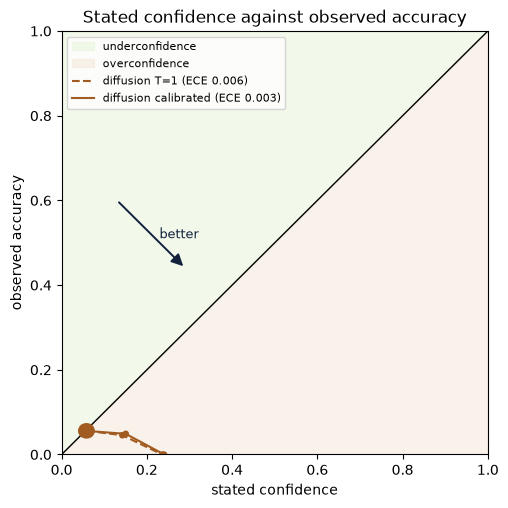

In [23]:
import torch
from slm import calibracao as cal, graficos
janelas_val, _ = janelar([d["ids"] for d in validacao], L)
janelas_val = janelas_val[torch.randperm(janelas_val.shape[0], generator=torch.Generator().manual_seed(0))]
Z, y = cal.coletar_previsoes(modelo, janelas_val, MODO, n_max=20000, dispositivo=DISPOSITIVO, sem_preenchimento=True)
T = cal.temperatura_newton(Z, y)
sistemas = {}
for rotulo, t in ((f"{MODO} T=1", 1.0), (f"{MODO} calibrated", T)):
    cf, ac = cal.confianca_acerto(Z, y, t)
    sistemas[rotulo] = dict(cal.confiabilidade(cf, ac), ece=cal.ece(cf, ac))
print(MODO, "| T =", round(T, 3), "| ROC AUC =", round(cal.auc_roc(*cal.confianca_acerto(Z, y, T)), 3))
fig = graficos.confiabilidade(sistemas, idioma="en")

### Technique

**A bound, not a value.** In diffusion, bits per byte come from the NELBO, which is an upper bound. If diffusion comes in below the autoregressive mode, it is better. If it comes in above, the gap may simply be slack in the bound. This asymmetric reading is declared before anything is run.

**Probability is not confidence.** The reliability diagram shows whether the stated confidence matches the observed accuracy. The temperature, fitted by Newton's method on validation, corrects the scale of the logits without changing which token is chosen.

## Box 9. Uncertainty

> **What changes from the autoregressive notebook.** Nothing. The interval across works and the rule for comparing the modes are the same in both notebooks.

### Theory

A number of bits per byte only becomes a claim together with its uncertainty. The project's protocol uses several seeds per mode and a bootstrap that resamples works and seeds. Here, with a single seed, the interval below resamples the works only, and so it measures variation between parts of the text, not between training runs. The comparison between the two modes uses the difference paired by seed, described in the blocks of this box, and the results of the full protocol are in `docs/`, in the repository.

### Building blocks

**Block 9.1, bootstrap by work.** Each replicate resamples the works with replacement, recomputes the bits per byte as a ratio of sums and stores the value. The interval runs from the 2.5th to the 97.5th percentile of the replicates. Resampling whole works respects the dependence between chapters of the same work.

**Block 9.2, seeds.** A single run cannot say how much the result varies with the initialisation and the order of the data. The project protocol trains several seeds and resamples at two levels, works and seeds. With $\hat\sigma$ estimated from $m$ pilot seeds, the upper bound is $\sigma_{sup} = \hat\sigma\sqrt{(m-1)/\chi^2_{0.025;\,m-1}}$, and the number of seeds is the smallest $n$ with $n \ge (t_{0.975;n-1} + t_{0.8;n-1})^2 (\sigma_{sup}/\Delta_{min})^2$.

**Block 9.3, comparison between the modes.** Seed $s$ fixes the initialisation and the data order in both modes, and the paired difference is $\Delta_s = \mathrm{bpb}_{dif,s} - \mathrm{bpb}_{AR,s}$. If the interval for $\Delta$ lies below zero, diffusion is better. If it lies above zero, the autoregressive mode beats the diffusion bound, which says nothing about the true likelihood of diffusion. If it contains zero, the result is inconclusive. This reading needs the runs of both notebooks, and the result of the full protocol is in `docs/`, in the repository. Code in `slm/estatistica.py`.

In [24]:
from slm.estatistica import fator_sigma_sup, numero_sementes
print("sigma_sup factor with 10 seeds:", round(fator_sigma_sup(10), 4))
for r in (0.5, 0.75, 1.0):
    print(f"sigma/Delta_min = {r}: n =", numero_sementes(r, 1.0, m=10).n)

sigma_sup factor with 10 seeds: 1.8256
sigma/Delta_min = 0.5: n = 9
sigma/Delta_min = 0.75: n = 17
sigma/Delta_min = 1.0: n = 29


### Application

In [25]:
import numpy as np
grupos = sorted({r["grupo"] for r in res["documentos"]})
por_grupo = {g: [(r["nats"], r["bytes"]) for r in res["documentos"] if r["grupo"] == g] for g in grupos}
rng = np.random.default_rng(0)
replicas = []
for _ in range(2000):
    escolha = rng.choice(grupos, size=len(grupos), replace=True)
    nats = sum(n for g in escolha for n, _ in por_grupo[g])
    nbytes = sum(b for g in escolha for _, b in por_grupo[g])
    replicas.append(nats / nbytes / np.log(2))
print(f"{MODO} | bpb = {res['bpb']:.4f} | 95% interval across works:", np.percentile(replicas, [2.5, 97.5]).round(4))

difusao | bpb = 2.7615 | 95% interval across works: [2.679  2.8373]


### Technique

**How many seeds?** With 3 seeds, the 95% interval for the standard deviation across seeds runs from 0.52 to 6.28 times the estimate. The project estimates the spread in a 10-seed pilot and derives from it the number of seeds for the final comparison, with a declared ceiling.

**Decide before looking.** The minimum effect size, the hyperparameter grid and the reading criterion are frozen with a hash before the runs they govern. Whenever a criterion had to change after the data were in, the change was recorded as an amendment, together with its justification.

## Box 10. Reading and memorisation

> **What changes from the autoregressive notebook.** The code is identical. The measurement of memorisation over many epochs appears only in the autoregressive notebook, because it was made in that mode.

### Theory

A model trained for many epochs on a small corpus can look coherent because it copies the training text. Before any human reading, each sample goes through two automatic filters, the share of its words found in the training lexicon (level N1) and the length of the longest span copied from the training text.

### Building blocks

**Block 10.1, lexicon rate.** $\rho(a) = \frac{|\{x \in \text{words}(a) : x \in \Lambda_{train}\}|}{|\text{words}(a)|}$, where $\Lambda_{train}$ is the lexicon of the training partition.

**Block 10.2, longest copied span.** $c(a) = \max\{k : \text{some span of } k \text{ words of } a \text{ occurs in the training text}\}$. The search hashes $k$-grams and runs a binary search on $k$, because whenever a span of $k$ words occurs all of its sub-spans occur as well, and the property is therefore monotone in $k$.

**Block 10.3, deletion curve.** With the decision $\hat y$ and $p_0 = p(\hat y \mid \text{full context})$, the importance of word $j$ is $p_0 - p(\hat y \mid \text{context without } j)$. Removing the $\mathrm{round}(f n)$ most important words gives $C(f) = \min\big(p(\hat y \mid \text{remaining context})/p_0, 1\big)$, and $\mathrm{AUC} = \int_0^1 C(f)\, df$ by the trapezoidal rule. $C(1)$ measures the intrinsic bias.

**Block 10.4, Spearman.** $\rho_S$ is the Pearson correlation between the ranks of $p_0$ and the ranks of the AUC, item by item. Code in `slm/leitura.py` and `slm/delecao.py`.

In [26]:
import numpy as np
from scipy.stats import rankdata, spearmanr
x10, y10 = np.array([0.2, 0.5, 0.1, 0.9]), np.array([0.7, 0.4, 0.8, 0.3])
print("Spearman by hand:", round(float(np.corrcoef(rankdata(x10), rankdata(y10))[0, 1]), 4),
      "| scipy:", round(float(spearmanr(x10, y10).statistic), 4))
grade = np.linspace(0, 1, 11)
C10 = np.array([1, .6, .5, .45, .4, .38, .36, .35, .34, .33, .33])
print("AUC by the trapezoidal rule:", round(float(np.trapezoid(C10, grade)), 4))

Spearman by hand: -1.0 | scipy: -1.0
AUC by the trapezoidal rule: 0.4375


### Application

In [27]:
from slm.leitura import IndiceTreino, lexico, taxa_lexico
textos_treino = [d["texto"] for d in ler_documentos(CORPUS, "treino")]
lex = lexico(textos_treino)
indice = IndiceTreino(textos_treino)
for a in amostras.tolist():
    t = como_texto(a)
    print("lexicon rate:", round(taxa_lexico(t, lex), 3), "| longest copied span:", indice.maior_trecho(t), "words")

lexicon rate: 0.652 | longest copied span: 3 words
lexicon rate: 0.644 | longest copied span: 2 words
lexicon rate: 0.665 | longest copied span: 3 words


### Deletion curve

How much does a prediction depend on its context? For each passage of 50 words, context words are removed, starting with those that most support the decision, and the probability of the decided token is followed relative to the original one. With 100% removed the context is empty, and what remains is the model's intrinsic bias. The curve with random order serves as a reference.

AUC by importance 0.977 | random 0.981 | empty context 0.963 | Spearman p0 x AUC -0.21


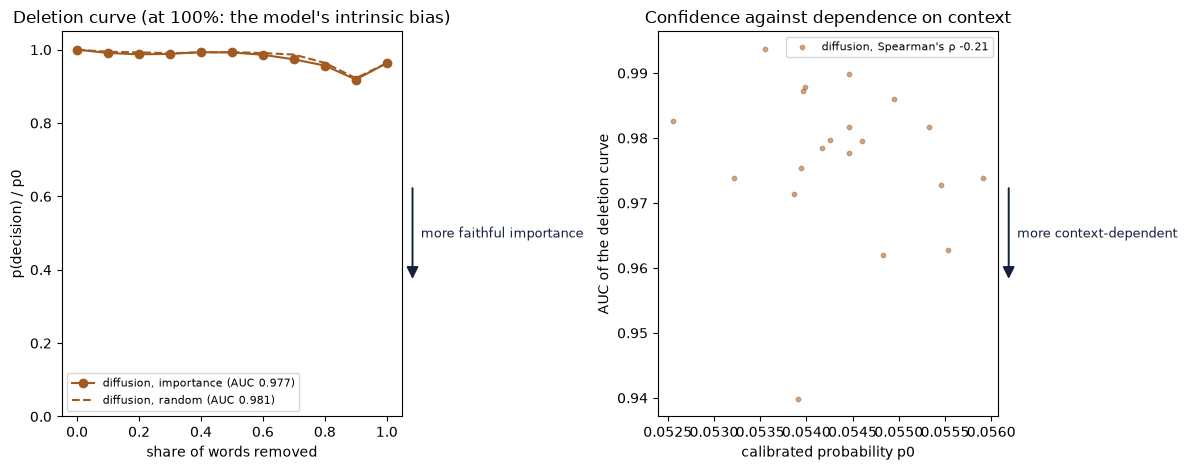

In [28]:
from slm import delecao
itens = delecao.itens([d["texto"] for d in ler_documentos(CORPUS, "teste")], tok, n_itens=20, n_palavras=50)
res_del = delecao.analisar(modelo, MODO, tok, itens, L, T=T, dispositivo=DISPOSITIVO)
print(f"AUC by importance {res_del['auc_importancia_media']:.3f} | random {res_del['auc_aleatoria_media']:.3f} | "
      f"empty context {res_del['p_vazio_relativo_medio']:.3f} | Spearman p0 x AUC {res_del['spearman_p0_auc']['rho']:.2f}")
fig = graficos.delecao({MODO: res_del}, idioma="en")

### Technique

**Coherent or copied?** A model trained for many epochs can look coherent because it reproduces passages of the training text. The copy filter measures the longest copied passage and discards any sample that goes beyond what is observed between human texts. The discard rate is reported as a measure of memorisation.

**The bias left without context.** On the deletion curve, with 100% of the context removed, the network still assigns probability to the original decision. This residue measures the model's intrinsic bias, what it knows without looking at the input.

## Exercises

1. In box 0, set `CORPUS = "B"` and run everything again. What changes in the code and what stays the same?
2. In box 7, lower `T_gen` to 8. What happens to the text, and why?
3. In box 0, double `EPOCAS_AULA`. Do the validation bits per byte fall in the same proportion as the training loss?
4. In box 6, why does the loss divide the sum of each window by its own $l$, rather than the sum of the whole batch by the total number of masks in the batch?
5. On the deletion curve, what does it mean for the curve to stay near 1 even with 100% of the context removed?
6. Run the notebook `slm_autoregressive.ipynb` with the same configuration and compare the bits per byte. What conclusion does the asymmetric reading of box 9 allow?

## References

The full list of references, all open access, is in `referencias/REFERENCIAS.md`, in the repository.